<a href="https://colab.research.google.com/github/itstrvor/30-days-of-python/blob/Report-on-political-tweets/Copy_of_Sentiment_Analysis_of_Kenyan_Political_Tweets_Comparing_Naive_Bayes_and_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Kenyan Social Media Sentiment Analysis
## Topic: Copy of Sentiment Analysis of Kenyan Political Tweets: Comparing Naive Bayes and Logistic Regression



## 1. Importing Libraries

In this section, we import the Python libraries required for data collection, data preprocessing, data visualization, and machine learning.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Project Overview

This project focuses on analyzing public opinions expressed in Kenyan political tweets using supervised machine learning techniques.

The dataset consists of social media posts discussing Kenyan political topics, particularly political figures and events involving Uhuru Kenyatta and William Ruto.

Each tweet is classified into one of three sentiment categories:

- Positive
- Negative
- Neutral

VADER is used to automatically generate preliminary sentiment labels. Two machine learning algorithms, Naive Bayes and Logistic Regression, are then trained and compared using accuracy, precision, recall, and F1-score.

The project aims to examine how machine learning can identify sentiment in Kenyan political discussions on social media and evaluate the performance and limitations of the two classification models.


## 3. Importing the Dataset

In this section, we upload and load the downloaded CSV file into Google Colab using Pandas.

We will inspect the dataset to understand its structure, columns, and available information before starting data preprocessing.


In [ ]:

from google.colab import files
uploaded = files.upload()

Saving kenya_political_tweets.xlsx to kenya_political_tweets (1).xlsx


## 4. Reading the Dataset
In this section, we load the uploaded CSV file into a Pandas DataFrame.

This allows us to access, inspect, and analyze the dataset using Python.

In [ ]:
import pandas as pd

df = pd.read_excel("kenya_political_tweets.xlsx")

print(df.shape)
print(df.columns.tolist())
df.head()

(11723, 16)
['id', 'user_name', 'user_location', 'user_description', 'user_created', 'user_followers', 'user_friends', 'user_favourites', 'user_verified', 'date', 'text', 'hashtags', 'source', 'retweets', 'favorites', 'is_retweet']


,id,user_name,user_location,user_description,user_created,user_followers,user_friends,user_favourites,user_verified,date,text,hashtags,source,retweets,favorites,is_retweet
0,1396091006030856192,Doomster,Utopia slums,"Alt-left, liberal, pronoun:them",2009-08-23 12:22:53,309.0,907,8050,0.0,2021-05-22 13:10:08,@PrettyAmmina The change to the new blue unifo...,NaN,Twitter Web App,0.0,0.0,0.0
1,1395981137764397056,Unruly ðŸ—¯,Morayfield,I don't know what you thought this was gonna b...,2011-04-20 19:35:54,1053.0,523,5279,0.0,2021-05-22 05:53:33,I think it's now safe to say President Uhuru K...,NaN,Twitter for Android,0.0,0.0,0.0
2,1395433210490798082,Khavin,Nairobi,CCTV installation and MAINTENANCE technician. ...,2020-02-11 04:52:44,4202.0,3735,29563,0.0,2021-05-20 17:36:17,@_CrazyKenyan President Uhuru Kenyatta bribed ...,['bbinonsense'],Twitter Web App,0.0,1.0,0.0
3,1394739630898044931,LecturerðŸ‡°ðŸ‡ªðŸ’¥,Eldoret,President Kenyatta's critic.William Samoei Rut...,2020-01-23 19:10:51,774.0,1467,4150,0.0,2021-05-18 19:40:15,"As @HonMoses_Kuria has just been saying,Presid...",NaN,Twitter for Android,0.0,0.0,0.0
4,1394561455471661057,LecturerðŸ‡°ðŸ‡ªðŸ’¥,Eldoret,President Kenyatta's critic.William Samoei Rut...,2020-01-23 19:10:51,774.0,1467,4150,0.0,2021-05-18 07:52:15,David Murathe the KEMSA thief and President Uh...,NaN,Twitter for Android,2.0,1.0,0.0


### 5.1 General Dataset Information

In this section, we examine the general structure of the dataset, including the number of entries, column names, and data types.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11723 entries, 0 to 11722
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                11723 non-null  object 
 1   user_name         11723 non-null  object 
 2   user_location     9239 non-null   object 
 3   user_description  10730 non-null  object 
 4   user_created      11722 non-null  object 
 5   user_followers    11722 non-null  object 
 6   user_friends      11722 non-null  object 
 7   user_favourites   11722 non-null  object 
 8   user_verified     11721 non-null  object 
 9   date              11722 non-null  object 
 10  text              11722 non-null  object 
 11  hashtags          1174 non-null   object 
 12  source            11722 non-null  object 
 13  retweets          11721 non-null  float64
 14  favorites         11721 non-null  float64
 15  is_retweet        11721 non-null  object 
dtypes: float64(2), object(14)
memory usage: 

### 5.2 Dataset Shape

In this section, we identify the total number of rows and columns in the dataset.

In [ ]:
print("Number of rows and columns:")
print(df.shape)

Number of rows and columns:
(11723, 16)


### 5.3 Column Names

In this section, we display all column names available in the dataset.

In [ ]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['id', 'user_name', 'user_location', 'user_description', 'user_created', 'user_followers', 'user_friends', 'user_favourites', 'user_verified', 'date', 'text', 'hashtags', 'source', 'retweets', 'favorites', 'is_retweet']


### 5.4 Data Types

In this section, we identify the data type of each column to understand how the information is stored.

In [ ]:
print("Data Types:")
print(df.dtypes)

Data Types:
id                   object
user_name            object
user_location        object
user_description     object
user_created         object
user_followers       object
user_friends         object
user_favourites      object
user_verified        object
date                 object
text                 object
hashtags             object
source               object
retweets            float64
favorites           float64
is_retweet           object
dtype: object


### 5.5 Missing Values

In this section, we check for missing or empty values in each column of the dataset.

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
id                      0
user_name               0
user_location        2484
user_description      993
user_created            1
user_followers          1
user_friends            1
user_favourites         1
user_verified           2
date                    1
text                    1
hashtags            10549
source                  1
retweets                2
favorites               2
is_retweet              2
dtype: int64


### 5.6 Duplicate Rows

In this section, we identify duplicate records in the dataset. Duplicate rows may affect the quality and reliability of our analysis.

In [ ]:
print("Duplicate Rows:")
print(df.duplicated().sum())

Duplicate Rows:
0


## 6. Data Preprocessing

### 6.1 Understanding the Dataset

In this section, we examine the first rows of the dataset to understand its content and identify the columns containing the text data and sentiment labels.

This step helps us prepare the correct columns for text preprocessing and machine learning.

In [ ]:
# Display the first 10 rows
df.head(10)

,id,user_name,user_location,user_description,user_created,user_followers,user_friends,user_favourites,user_verified,date,text,hashtags,source,retweets,favorites,is_retweet
0,1396091006030856192,Doomster,Utopia slums,"Alt-left, liberal, pronoun:them",2009-08-23 12:22:53,309.0,907,8050,0.0,2021-05-22 13:10:08,@PrettyAmmina The change to the new blue unifo...,NaN,Twitter Web App,0.0,0.0,0.0
1,1395981137764397056,Unruly ðŸ—¯,Morayfield,I don't know what you thought this was gonna b...,2011-04-20 19:35:54,1053.0,523,5279,0.0,2021-05-22 05:53:33,I think it's now safe to say President Uhuru K...,NaN,Twitter for Android,0.0,0.0,0.0
2,1395433210490798082,Khavin,Nairobi,CCTV installation and MAINTENANCE technician. ...,2020-02-11 04:52:44,4202.0,3735,29563,0.0,2021-05-20 17:36:17,@_CrazyKenyan President Uhuru Kenyatta bribed ...,['bbinonsense'],Twitter Web App,0.0,1.0,0.0
3,1394739630898044931,LecturerðŸ‡°ðŸ‡ªðŸ’¥,Eldoret,President Kenyatta's critic.William Samoei Rut...,2020-01-23 19:10:51,774.0,1467,4150,0.0,2021-05-18 19:40:15,"As @HonMoses_Kuria has just been saying,Presid...",NaN,Twitter for Android,0.0,0.0,0.0
4,1394561455471661057,LecturerðŸ‡°ðŸ‡ªðŸ’¥,Eldoret,President Kenyatta's critic.William Samoei Rut...,2020-01-23 19:10:51,774.0,1467,4150,0.0,2021-05-18 07:52:15,David Murathe the KEMSA thief and President Uh...,NaN,Twitter for Android,2.0,1.0,0.0
5,1394334198417215493,LecturerðŸ‡°ðŸ‡ªðŸ’¥,Eldoret,President Kenyatta's critic.William Samoei Rut...,2020-01-23 19:10:51,774.0,1467,4150,0.0,2021-05-17 16:49:13,The Kenyan Senate despite having several elite...,NaN,Twitter for Android,0.0,0.0,0.0
6,1394014196610781189,LecturerðŸ‡°ðŸ‡ªðŸ’¥,Eldoret,President Kenyatta's critic.William Samoei Rut...,2020-01-23 19:10:51,774.0,1467,4150,0.0,2021-05-16 19:37:38,Somebody tell CS Peter Munya to die before 202...,NaN,Twitter for Android,0.0,1.0,0.0
7,1393619973524832257,G.G Peter Atom,Nairobi,"God Gave me wisdom, empowered me to search for...",2011-10-06 08:19:42,117.0,308,1839,0.0,2021-05-15 17:31:08,ICC called him Mr. Kenyatta for they did not r...,NaN,Twitter for Android,0.0,0.0,0.0
8,1393618298684727298,Nyandarua County Government,Kenya,Official twitter account of Nyandarua County G...,2016-10-13 14:25:52,1926.0,170,361,0.0,2021-05-15 17:24:29,The leaders urged residents of the Central Reg...,NaN,Twitter for Android,0.0,0.0,0.0
9,1393615018642579461,Suleiman H Sandhere,Somaliland,8th president of the Republic of Somaliland. I...,2017-06-19 19:52:31,59.0,335,66,0.0,2021-05-15 17:11:27,Three leaders of Horn of AfricaðŸ‘‡\n1. Presid...,NaN,Twitter for Android,0.0,0.0,0.0


### 6.2 Checking Text and Sentiment Columns

In this section, we identify the columns that contain textual data and sentiment labels.

These columns are essential for training our supervised machine learning models.

In [ ]:
# Display all column names
for column in df.columns:
    print(column)

id
user_name
user_location
user_description
user_created
user_followers
user_friends
user_favourites
user_verified
date
text
hashtags
source
retweets
favorites
is_retweet


### 6.3 Inspecting Tweet Text

In this section, we examine sample tweets from the dataset to understand their content, language, and relevance to our research topic.

This helps us determine whether the text data is suitable for sentiment analysis.

In [ ]:
# Display 10 sample tweets
for i, tweet in enumerate(df["text"].head(10), start=1):
    print(f"\nTweet {i}:")
    print(tweet)


Tweet 1:
@PrettyAmmina The change to the new blue uniforms was ordered by President Uhuru Kenyatta in September 2019, as parâ€¦ https://t.co/NEnbULE4xy

Tweet 2:
I think it's now safe to say President Uhuru Kenyatta amepatia Justice Martha Koome CJ ðŸ˜… https://t.co/Q9YQMAy5HN

Tweet 3:
@_CrazyKenyan President Uhuru Kenyatta bribed MCAs, Mpigs and senators
So your are crucifying Dp Ruto for sinning differently
#bbinonsense

Tweet 4:
As @HonMoses_Kuria has just been saying,President Uhuru Kenyatta should finish and ago. Mt Kenya has new kingpins wâ€¦ https://t.co/pcP10g77wf

Tweet 5:
David Murathe the KEMSA thief and President Uhuru Kenyatta's advisor together with Rafael Tuju should get ready toâ€¦ https://t.co/PWro5H4pAS

Tweet 6:
The Kenyan Senate despite having several elites still lacks Consistency when it comes to matters at hand.The proposâ€¦ https://t.co/btzOqTyH3b

Tweet 7:
Somebody tell CS Peter Munya to die before 2022 if he is not ready to see DP Ruto as the 5th President o

### 6.5 Checking Missing Tweet Text

In this section, we check whether some tweets have missing text values.

Missing text records cannot be used for sentiment analysis and may need to be removed.

In [ ]:
# Count missing values in the text column
print("Missing tweets:", df["text"].isnull().sum())

Missing tweets: 1


### 6.6 Checking Duplicate Tweets

In this section, we identify repeated tweets in the dataset.

Duplicate tweets may affect the reliability of our sentiment analysis.

In [ ]:
print("Duplicate tweets:", df["text"].duplicated().sum())

Duplicate tweets: 117


### 6.7 Checking Tweet Languages

In this section, we examine the languages used in the tweets.

This is important because the project focuses on Kenyan social media content, including English, Swahili, and Sheng.

In [ ]:
# Display 20 random tweets for language inspection
df["text"].dropna().sample(20, random_state=42)

,text
101,Course. In 2020 Shot By The Presidential Guard...
5272,William Ruto is right to point out that Kenyaâ...
5147,@waluwande @DonaldBKipkorir UDA is actually a ...
9222,Good morning from William samoei Ruto also fro...
1845,President Uhuru Kenyatta presided over the eve...
3274,OFFER!!! OFFER!!! \nDouble-Sided Binded Duvets...
10514,William Ruto has never been Uhuru Kenyattaâ€™s...
10502,@Kenyans @HonMosesKuria William Ruto is a Thie...
10989,William Rutoâ€™s game plan ahead of 2022 elect...
3024,"WON!! AFTER LOSING DAILY TO SCAMMERS, THIS GUY..."


### 6.8 Checking Empty and Irrelevant Tweets

In this section, we inspect tweets that may contain irrelevant promotional content or empty text.

This helps us identify records that may not contribute meaningfully to our political sentiment analysis.

In [ ]:
# Display 10 tweets with the shortest text
df["text"].dropna().loc[
    df["text"].dropna().str.len().nsmallest(10).index
]

,text
5004,William ruto
5947,William ruto
9167,William ruto
9489,William ruto
10089,William Ruto
10442,William ruto
11393,William ruto
10724,Dr William ruto
11364,William Ruto live
11365,William Ruto live


### 6.9 Removing Missing and Duplicate Tweets

In this section, we clean the dataset by removing records with missing or empty tweet text and eliminating duplicate tweets.

We create a cleaned copy of the original dataset to preserve the raw data.

This improves data quality before further text preprocessing.

In [ ]:
# Create a working copy of the original dataset
df_clean = df.copy()

# Remove tweets with missing text
df_clean = df_clean.dropna(subset=["text"])

# Remove leading and trailing spaces
df_clean["text"] = df_clean["text"].astype(str).str.strip()

# Remove empty tweets
df_clean = df_clean[df_clean["text"] != ""]

# Remove duplicate tweets
df_clean = df_clean.drop_duplicates(subset=["text"])

# Display cleaning results
print("Original dataset:", len(df))
print("Cleaned dataset:", len(df_clean))
print("Remaining missing tweets:", df_clean["text"].isnull().sum())
print("Remaining duplicate tweets:", df_clean["text"].duplicated().sum())

Original dataset: 11723
Cleaned dataset: 11605
Remaining missing tweets: 0
Remaining duplicate tweets: 0


### 6.10 Removing URLs

In this section, we remove URLs from the normalized tweet text.

Links do not usually contribute directly to sentiment classification, so removing them helps simplify the text data

### 6.10.1 Recreating the Clean Text Column

In this section, we recreate the `clean_text` column by converting tweets to lowercase and removing unnecessary extra spaces.

This ensures that the text normalization step is completed before removing URLs.

In [ ]:
# Convert tweets to lowercase
df_clean["clean_text"] = df_clean["text"].str.lower()

# Remove extra spaces
df_clean["clean_text"] = (
    df_clean["clean_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Text normalization completed successfully!")

Text normalization completed successfully!


In [ ]:
# Remove URLs from tweets
df_clean["clean_text"] = df_clean["clean_text"].str.replace(
    r"http\S+|www\S+",
    "",
    regex=True
)

# Remove extra spaces
df_clean["clean_text"] = df_clean["clean_text"].str.strip()

# Display the results
df_clean[["text", "clean_text"]].head(10)

,text,clean_text
0,@PrettyAmmina The change to the new blue unifo...,@prettyammina the change to the new blue unifo...
1,I think it's now safe to say President Uhuru K...,i think it's now safe to say president uhuru k...
2,@_CrazyKenyan President Uhuru Kenyatta bribed ...,@_crazykenyan president uhuru kenyatta bribed ...
3,"As @HonMoses_Kuria has just been saying,Presid...","as @honmoses_kuria has just been saying,presid..."
4,David Murathe the KEMSA thief and President Uh...,david murathe the kemsa thief and president uh...
5,The Kenyan Senate despite having several elite...,the kenyan senate despite having several elite...
6,Somebody tell CS Peter Munya to die before 202...,somebody tell cs peter munya to die before 202...
7,ICC called him Mr. Kenyatta for they did not r...,icc called him mr. kenyatta for they did not r...
8,The leaders urged residents of the Central Reg...,the leaders urged residents of the central reg...
9,Three leaders of Horn of AfricaðŸ‘‡\n1. Presid...,three leaders of horn of africaðÿ‘‡ 1. preside...


### 6.12 Removing User Mentions

In this section, we remove Twitter user mentions such as @username from the tweet text.

These mentions identify specific accounts but usually do not provide meaningful information for sentiment classification.

In [ ]:
# Remove Twitter user mentions
df_clean["clean_text"] = df_clean["clean_text"].str.replace(
    r"@\w+",
    "",
    regex=True
)

# Remove extra spaces
df_clean["clean_text"] = df_clean["clean_text"].str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

# Display original and cleaned tweets
df_clean[["text", "clean_text"]].head(10)

,text,clean_text
0,@PrettyAmmina The change to the new blue unifo...,the change to the new blue uniforms was ordere...
1,I think it's now safe to say President Uhuru K...,i think it's now safe to say president uhuru k...
2,@_CrazyKenyan President Uhuru Kenyatta bribed ...,"president uhuru kenyatta bribed mcas, mpigs an..."
3,"As @HonMoses_Kuria has just been saying,Presid...","as has just been saying,president uhuru kenyat..."
4,David Murathe the KEMSA thief and President Uh...,david murathe the kemsa thief and president uh...
5,The Kenyan Senate despite having several elite...,the kenyan senate despite having several elite...
6,Somebody tell CS Peter Munya to die before 202...,somebody tell cs peter munya to die before 202...
7,ICC called him Mr. Kenyatta for they did not r...,icc called him mr. kenyatta for they did not r...
8,The leaders urged residents of the Central Reg...,the leaders urged residents of the central reg...
9,Three leaders of Horn of AfricaðŸ‘‡\n1. Presid...,three leaders of horn of africaðÿ‘‡ 1. preside...


### 6.13 Removing Special Characters

In this section, we remove unnecessary special characters, punctuation marks, and symbols from the tweet text.

This helps standardize the text while preserving letters, numbers, and spaces.

In [ ]:
# Remove special characters and punctuation
df_clean["clean_text"] = df_clean["clean_text"].str.replace(
    r"[^a-zA-Z0-9\s]",
    "",
    regex=True
)

# Remove extra spaces
df_clean["clean_text"] = df_clean["clean_text"].str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

# Display original and cleaned tweets
df_clean[["text", "clean_text"]].head(10)

,text,clean_text
0,@PrettyAmmina The change to the new blue unifo...,the change to the new blue uniforms was ordere...
1,I think it's now safe to say President Uhuru K...,i think its now safe to say president uhuru ke...
2,@_CrazyKenyan President Uhuru Kenyatta bribed ...,president uhuru kenyatta bribed mcas mpigs and...
3,"As @HonMoses_Kuria has just been saying,Presid...",as has just been sayingpresident uhuru kenyatt...
4,David Murathe the KEMSA thief and President Uh...,david murathe the kemsa thief and president uh...
5,The Kenyan Senate despite having several elite...,the kenyan senate despite having several elite...
6,Somebody tell CS Peter Munya to die before 202...,somebody tell cs peter munya to die before 202...
7,ICC called him Mr. Kenyatta for they did not r...,icc called him mr kenyatta for they did not re...
8,The leaders urged residents of the Central Reg...,the leaders urged residents of the central reg...
9,Three leaders of Horn of AfricaðŸ‘‡\n1. Presid...,three leaders of horn of africa 1 president re...


### 6.14 Removing Numbers

In this section, we remove numerical characters from the tweet text.

This helps reduce unnecessary numerical information that may not contribute to sentiment classification.

In [ ]:
# Remove numbers from tweets
df_clean["clean_text"] = df_clean["clean_text"].str.replace(
    r"\d+",
    "",
    regex=True
)

# Remove extra spaces
df_clean["clean_text"] = df_clean["clean_text"].str.replace(
    r"\s+",
    " ",
    regex=True
).str.strip()

# Display cleaned tweets
df_clean[["text", "clean_text"]].head(10)

,text,clean_text
0,@PrettyAmmina The change to the new blue unifo...,the change to the new blue uniforms was ordere...
1,I think it's now safe to say President Uhuru K...,i think its now safe to say president uhuru ke...
2,@_CrazyKenyan President Uhuru Kenyatta bribed ...,president uhuru kenyatta bribed mcas mpigs and...
3,"As @HonMoses_Kuria has just been saying,Presid...",as has just been sayingpresident uhuru kenyatt...
4,David Murathe the KEMSA thief and President Uh...,david murathe the kemsa thief and president uh...
5,The Kenyan Senate despite having several elite...,the kenyan senate despite having several elite...
6,Somebody tell CS Peter Munya to die before 202...,somebody tell cs peter munya to die before if ...
7,ICC called him Mr. Kenyatta for they did not r...,icc called him mr kenyatta for they did not re...
8,The leaders urged residents of the Central Reg...,the leaders urged residents of the central reg...
9,Three leaders of Horn of AfricaðŸ‘‡\n1. Presid...,three leaders of horn of africa president repu...


### 6.15 Checking Empty Text After Cleaning

In this section, we identify tweets that became empty after text preprocessing.

These records do not contain useful textual information for sentiment analysis and may need to be removed.

In [ ]:
# Count empty tweets after cleaning
empty_tweets = (df_clean["clean_text"] == "").sum()

print("Empty tweets after cleaning:", empty_tweets)

Empty tweets after cleaning: 36


### 6.16 Removing Empty Tweets

In this section, we remove tweets that became empty after text preprocessing.

This ensures that the remaining dataset contains usable text for sentiment analysis.

In [ ]:
# Remove empty tweets
df_clean = df_clean[df_clean["clean_text"] != ""].copy()

# Display the updated dataset size
print("Dataset size after removing empty tweets:", len(df_clean))

# Verify that no empty tweets remain
print("Remaining empty tweets:", (df_clean["clean_text"] == "").sum())

Dataset size after removing empty tweets: 11569
Remaining empty tweets: 0


### 6.16 Removing Empty Tweets

During text preprocessing, 36 tweets became empty after removing URLs, user mentions, special characters, and numbers.

These tweets were removed because they no longer contained useful textual information for sentiment analysis.

In [ ]:
# Remove empty tweets
df_clean = df_clean[df_clean["clean_text"] != ""].copy()

# Record the updated dataset size
print("Dataset before removing empty tweets: 11,605")
print("Empty tweets removed: 36")
print("Dataset after removing empty tweets:", len(df_clean))

Dataset before removing empty tweets: 11,605
Empty tweets removed: 36
Dataset after removing empty tweets: 11569


### 6.17 Final Dataset Verification

In this section, we verify the size and quality of the cleaned dataset after removing empty tweets.

We check the remaining records and confirm that the text column is ready for sentiment annotation.

In [ ]:
# Display final dataset statistics
print("FINAL CLEANED DATASET")
print("----------------------")
print("Total tweets:", len(df_clean))
print("Missing text values:", df_clean["clean_text"].isnull().sum())
print("Empty text values:", (df_clean["clean_text"] == "").sum())
print("Duplicate cleaned tweets:", df_clean["clean_text"].duplicated().sum())

# Display 5 cleaned examples
df_clean[["text", "clean_text"]].head()

FINAL CLEANED DATASET
----------------------
Total tweets: 11569
Missing text values: 0
Empty text values: 0
Duplicate cleaned tweets: 1108


,text,clean_text
0,@PrettyAmmina The change to the new blue unifo...,the change to the new blue uniforms was ordere...
1,I think it's now safe to say President Uhuru K...,i think its now safe to say president uhuru ke...
2,@_CrazyKenyan President Uhuru Kenyatta bribed ...,president uhuru kenyatta bribed mcas mpigs and...
3,"As @HonMoses_Kuria has just been saying,Presid...",as has just been sayingpresident uhuru kenyatt...
4,David Murathe the KEMSA thief and President Uh...,david murathe the kemsa thief and president uh...


### 7.1 Selecting the Tweets for Annotation

In this section, we select a random sample of 1,000 tweets from the cleaned dataset.

The sample will be used for manual sentiment annotation.

Each tweet will later be classified as positive, negative, or neutral.

In [ ]:
# Select 1,000 random tweets
annotation_df = df_clean[["text", "clean_text"]].sample(
    n=1000,
    random_state=42
).copy()

# Create an empty sentiment column
annotation_df["sentiment"] = ""

print("Tweets selected for annotation:", len(annotation_df))

# Display the first 10 selected tweets
annotation_df.head(10)

Tweets selected for annotation: 1000


,text,clean_text,sentiment
9881,Matchless depth of Love[Though death could kil...,matchless depth of lovethough death could kill...,
8908,I thought tuliambiwa Raila Odinga will teach U...,i thought tuliambiwa raila odinga will teach u...,
4756,@CisNyakundi Then on crossfire Murathe will be...,then on crossfire murathe will be like is this...,
5082,Dear president Uhuru Kenyatta and State house...,dear president uhuru kenyatta and state house ...,
9726,@MigunaTEAM Kalonzo Musyoka is just like Tony ...,kalonzo musyoka is just like tony gachoka who ...,
4364,A failed president with his deputy Dr William ...,a failed president with his deputy dr william ...,
7266,@Sndunda1 @RodgersKipembe @WilliamsRuto @Danie...,they are opening battle fronts everywhere they...,
10691,@WilliamsRuto I will vote for William Ruto\n#h...,i will vote for william ruto hustlernation,
8339,RAILA ODINGA mourns CHRIS KIRUBI â€“ I have lo...,raila odinga mourns chris kirubi i have lost a...,
1651,President Uhuru Kenyatta will on Thursday lead...,president uhuru kenyatta will on thursday lead...,


### 7.2 Creating Sentiment Labels

In this section, we use the VADER sentiment analysis tool to automatically assign preliminary sentiment labels to the 1,000 selected tweets.

VADER calculates sentiment scores and classifies each tweet as positive, negative, or neutral.

The automatically generated labels will be checked before model training because VADER may not correctly interpret Kenyan political expressions, Swahili, and Sheng.

In [ ]:
# Install VADER
!pip install vaderSentiment

# Import the sentiment analyzer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

# Assign sentiment labels
def classify_sentiment(text):
    score = analyzer.polarity_scores(str(text))["compound"]

    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"

# Apply sentiment classification
annotation_df["sentiment"] = annotation_df["clean_text"].apply(classify_sentiment)

# Display the results
print("Sentiment annotation completed!")
print(annotation_df["sentiment"].value_counts())

Sentiment annotation completed!
sentiment
positive    373
neutral     362
negative    265
Name: count, dtype: int64


### 7.3 Checking the Annotated Dataset

In this section, we verify the automatically annotated dataset.

VADER assigned sentiment labels to all 1,000 tweets:

- Positive: 373 tweets (37.3%)
- Neutral: 362 tweets (36.2%)
- Negative: 265 tweets (26.5%)

We check for missing sentiment labels and inspect sample records to ensure that the annotation process was completed.

These labels are preliminary and may contain errors, particularly for Swahili and Sheng expressions.

In [ ]:
# Verify the annotated dataset
print("Total annotated tweets:", len(annotation_df))
print("Missing sentiment labels:", annotation_df["sentiment"].isnull().sum())
print("Empty sentiment labels:", (annotation_df["sentiment"] == "").sum())

print("\nSentiment distribution:")
print(annotation_df["sentiment"].value_counts())

# Display 10 annotated tweets
annotation_df[["text", "sentiment"]].head(10)

Total annotated tweets: 1000
Missing sentiment labels: 0
Empty sentiment labels: 0

Sentiment distribution:
sentiment
positive    373
neutral     362
negative    265
Name: count, dtype: int64


,text,sentiment
9881,Matchless depth of Love[Though death could kil...,negative
8908,I thought tuliambiwa Raila Odinga will teach U...,neutral
4756,@CisNyakundi Then on crossfire Murathe will be...,positive
5082,Dear president Uhuru Kenyatta and State house...,negative
9726,@MigunaTEAM Kalonzo Musyoka is just like Tony ...,positive
4364,A failed president with his deputy Dr William ...,negative
7266,@Sndunda1 @RodgersKipembe @WilliamsRuto @Danie...,negative
10691,@WilliamsRuto I will vote for William Ruto\n#h...,neutral
8339,RAILA ODINGA mourns CHRIS KIRUBI â€“ I have lo...,negative
1651,President Uhuru Kenyatta will on Thursday lead...,neutral


### 7.4 Saving the Annotated Dataset

In this section, we save the annotated dataset containing 1,000 tweets and their automatically generated sentiment labels.

The saved CSV file will be used in the next stage of the project: model training.

In [ ]:
# Save the annotated dataset
annotation_df.to_csv("kenyan_political_tweets_annotated.csv", index=False)

print("Annotated dataset saved successfully!")
print("Total tweets saved:", len(annotation_df))

Annotated dataset saved successfully!
Total tweets saved: 1000


## 8. Model Training

### 8.1 Splitting the Dataset

The annotated dataset contains 1,000 tweets:

- 800 tweets (80%) will be used for training.
- 200 tweets (20%) will be used for testing.

Stratified sampling is used to preserve the distribution of positive, neutral, and negative sentiment labels in both datasets.

In [ ]:
# Import the required function
from sklearn.model_selection import train_test_split

# Define the input text and target labels
X = annotation_df["clean_text"]
y = annotation_df["sentiment"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("Total tweets:", len(annotation_df))
print("Training tweets:", len(X_train))
print("Testing tweets:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Total tweets: 1000
Training tweets: 800
Testing tweets: 200

Training sentiment distribution:
sentiment
positive    298
neutral     290
negative    212
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
positive    75
neutral     72
negative    53
Name: count, dtype: int64


### 8.2 Training the Naive Bayes Model

In this section, we train a Multinomial Naive Bayes classifier.

TF-IDF converts the tweet text into numerical features based on word importance.

The model learns from the 800 training tweets and their sentiment labels.

The testing data remains separate and will only be used during model evaluation.

In [ ]:
# Import the required tools
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

# Create the Naive Bayes pipeline
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

# Train the model
nb_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")
print("Training tweets:", len(X_train))

Naive Bayes model trained successfully!
Training tweets: 800


### 8.3 Training the Logistic Regression Model

In this section, we train a Logistic Regression classifier using the same 800 training tweets.

TF-IDF converts the text into numerical features, while Logistic Regression learns to classify tweets into positive, negative, and neutral categories.

This model will later be compared with the Naive Bayes classifier using the same testing dataset.

In [ ]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression pipeline
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")
print("Training tweets:", len(X_train))

Logistic Regression model trained successfully!
Training tweets: 800


## 9. Model Evaluation

### 9.1 Making Predictions

In this section, both trained models make sentiment predictions on the 200 testing tweets.

Their predictions will be compared with the sentiment labels generated by VADER.

The testing dataset was not used during model training.

In [ ]:
# Make predictions using both models
nb_predictions = nb_model.predict(X_test)
lr_predictions = lr_model.predict(X_test)

print("Predictions completed successfully!")
print("Naive Bayes predictions:", len(nb_predictions))
print("Logistic Regression predictions:", len(lr_predictions))

# Display sample predictions
results_df = pd.DataFrame({
    "Actual Sentiment": y_test.values,
    "Naive Bayes Prediction": nb_predictions,
    "Logistic Regression Prediction": lr_predictions
})

results_df.head(10)

Predictions completed successfully!
Naive Bayes predictions: 200
Logistic Regression predictions: 200


,Actual Sentiment,Naive Bayes Prediction,Logistic Regression Prediction
0,negative,positive,negative
1,negative,negative,negative
2,positive,negative,negative
3,neutral,positive,positive
4,negative,positive,neutral
5,neutral,positive,negative
6,positive,positive,positive
7,negative,positive,positive
8,neutral,neutral,neutral
9,neutral,neutral,neutral


### 9.2 Calculating Performance Metrics

In this section, we evaluate both models using four performance metrics:

- Accuracy
- Weighted Precision
- Weighted Recall
- Weighted F1-score

Both models are evaluated against the same 200 testing tweets and their VADER-generated sentiment labels.

The results will be used to compare the performance of Naive Bayes and Logistic Regression.

In [ ]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate Naive Bayes metrics
nb_metrics = {
    "Accuracy": accuracy_score(y_test, nb_predictions),
    "Precision": precision_score(y_test, nb_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, nb_predictions, average="weighted", zero_division=0),
    "F1-score": f1_score(y_test, nb_predictions, average="weighted", zero_division=0)
}

# Calculate Logistic Regression metrics
lr_metrics = {
    "Accuracy": accuracy_score(y_test, lr_predictions),
    "Precision": precision_score(y_test, lr_predictions, average="weighted", zero_division=0),
    "Recall": recall_score(y_test, lr_predictions, average="weighted", zero_division=0),
    "F1-score": f1_score(y_test, lr_predictions, average="weighted", zero_division=0)
}

# Create comparison table
metrics_df = pd.DataFrame({
    "Naive Bayes": nb_metrics,
    "Logistic Regression": lr_metrics
})

print("MODEL PERFORMANCE COMPARISON")
display(metrics_df.round(4))

MODEL PERFORMANCE COMPARISON


,Naive Bayes,Logistic Regression
Accuracy,0.5450,0.5850
Precision,0.6190,0.5844
Recall,0.5450,0.5850
F1-score,0.5227,0.5779


### 9.3 Classification Report

In this section, we generate a detailed classification report for both models.

The report shows precision, recall, F1-score, and support for each sentiment category: positive, negative, and neutral.

This helps identify which sentiment categories are more difficult for the models to classify.

In [ ]:
from sklearn.metrics import classification_report

print("NAIVE BAYES CLASSIFICATION REPORT")
print(classification_report(y_test, nb_predictions, zero_division=0))

print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(y_test, lr_predictions, zero_division=0))

NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.87      0.25      0.38        53
     neutral       0.57      0.51      0.54        72
    positive       0.49      0.79      0.61        75

    accuracy                           0.55       200
   macro avg       0.64      0.52      0.51       200
weighted avg       0.62      0.55      0.52       200


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.57      0.38      0.45        53
     neutral       0.54      0.62      0.58        72
    positive       0.63      0.69      0.66        75

    accuracy                           0.58       200
   macro avg       0.58      0.57      0.57       200
weighted avg       0.58      0.58      0.58       200



### 9.4 Confusion Matrix

In this section, we generate confusion matrices for both classification models.

The matrices compare the actual sentiment labels with the predicted labels.

They help identify which sentiment categories are most frequently misclassified.

In [ ]:
from sklearn.metrics import confusion_matrix

# Define the sentiment order
labels = ["negative", "neutral", "positive"]

# Generate confusion matrices
nb_cm = confusion_matrix(y_test, nb_predictions, labels=labels)
lr_cm = confusion_matrix(y_test, lr_predictions, labels=labels)

print("NAIVE BAYES CONFUSION MATRIX")
print("Rows = Actual | Columns = Predicted")
print(pd.DataFrame(nb_cm, index=labels, columns=labels))

print("\nLOGISTIC REGRESSION CONFUSION MATRIX")
print("Rows = Actual | Columns = Predicted")
print(pd.DataFrame(lr_cm, index=labels, columns=labels))

NAIVE BAYES CONFUSION MATRIX
Rows = Actual | Columns = Predicted
          negative  neutral  positive
negative        13       13        27
neutral          1       37        34
positive         1       15        59

LOGISTIC REGRESSION CONFUSION MATRIX
Rows = Actual | Columns = Predicted
          negative  neutral  positive
negative        20       20        13
neutral         10       45        17
positive         5       18        52


### 9.5 Visualizing the Confusion Matrices

In this section, we visualize the confusion matrices of Naive Bayes and Logistic Regression using heatmaps.

The diagonal cells represent correctly classified tweets, while the other cells represent classification errors.

These visualizations make it easier to compare the performance of both models across the three sentiment categories.

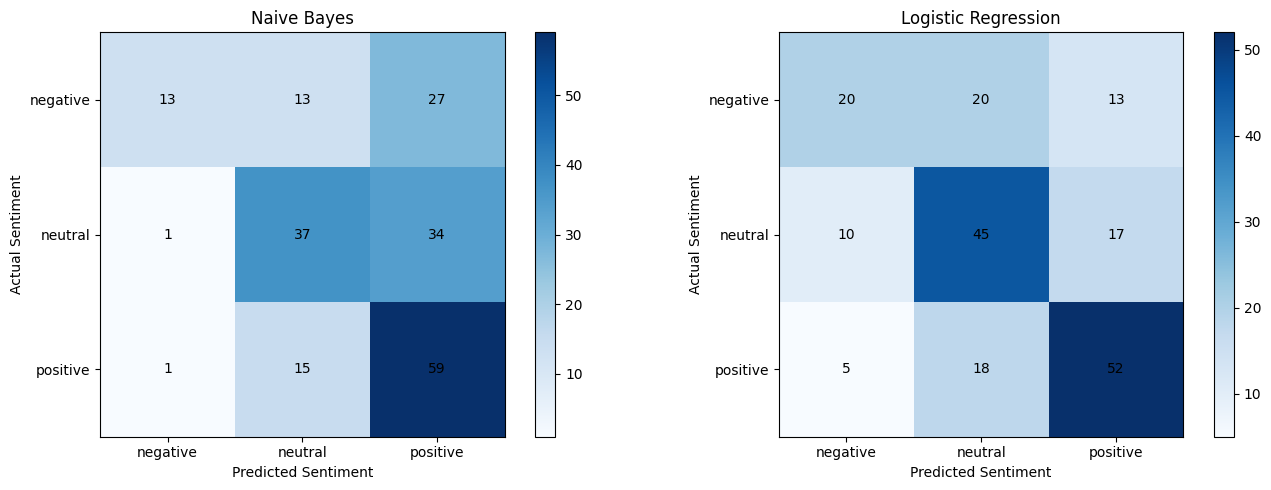

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

matrices = [
    (nb_cm, "Naive Bayes"),
    (lr_cm, "Logistic Regression")
]

for ax, (matrix, title) in zip(axes, matrices):
    image = ax.imshow(matrix, cmap="Blues")

    ax.set_title(title)
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)

    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, matrix[i, j], ha="center", va="center")

    fig.colorbar(image, ax=ax)

plt.tight_layout()
plt.show()

### 9.5 Visualizing the Confusion Matrices

Heatmaps provide a visual representation of the confusion matrices.
They help identify correct predictions and classification errors for each sentiment class.

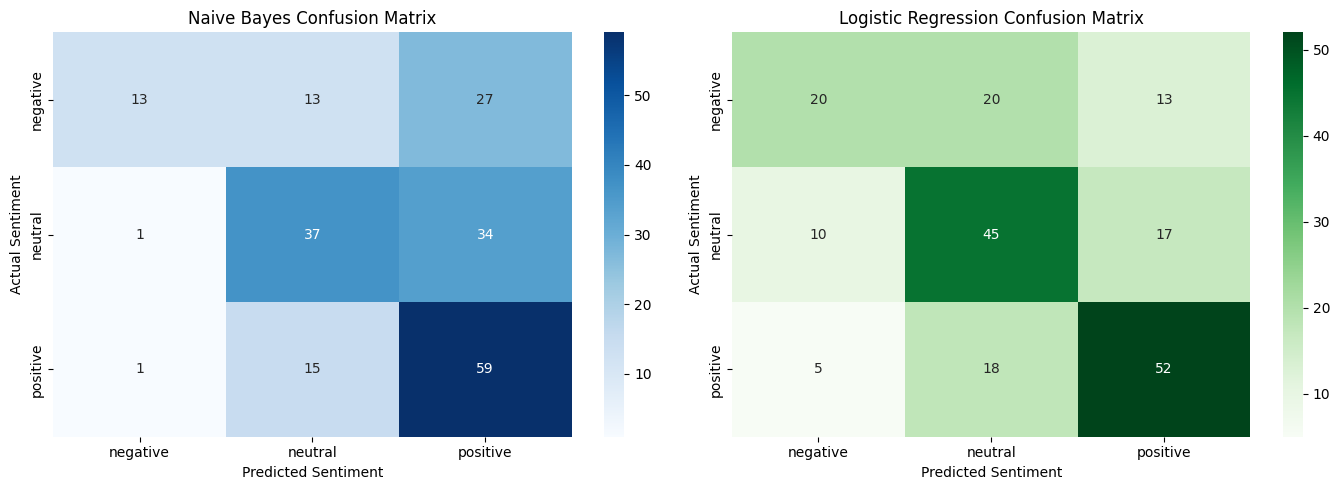

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Naive Bayes heatmap
sns.heatmap(
    nb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0]
)
axes[0].set_title("Naive Bayes Confusion Matrix")
axes[0].set_xlabel("Predicted Sentiment")
axes[0].set_ylabel("Actual Sentiment")

# Logistic Regression heatmap
sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1]
)
axes[1].set_title("Logistic Regression Confusion Matrix")
axes[1].set_xlabel("Predicted Sentiment")
axes[1].set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

### 10.1 Identifying Misclassified Tweets

This step identifies tweets that were incorrectly classified by each model.
It helps us understand the types of errors made during sentiment prediction.

In [ ]:
# Create a DataFrame containing actual and predicted sentiments
error_df = pd.DataFrame({
    "Tweet": X_test.values,
    "Actual Sentiment": y_test.values,
    "Naive Bayes Prediction": nb_predictions,
    "Logistic Regression Prediction": lr_predictions
})

# Identify incorrect predictions
nb_errors = error_df[
    error_df["Actual Sentiment"] != error_df["Naive Bayes Prediction"]
]

lr_errors = error_df[
    error_df["Actual Sentiment"] != error_df["Logistic Regression Prediction"]
]

print("Naive Bayes errors:", len(nb_errors))
print("Logistic Regression errors:", len(lr_errors))

print("\nNAIVE BAYES MISCLASSIFIED TWEETS")
display(nb_errors.head(10))

print("\nLOGISTIC REGRESSION MISCLASSIFIED TWEETS")
display(lr_errors.head(10))

Naive Bayes errors: 91
Logistic Regression errors: 83

NAIVE BAYES MISCLASSIFIED TWEETS


,Tweet,Actual Sentiment,Naive Bayes Prediction,Logistic Regression Prediction
0,william ruto and cohorts should not expect rid...,negative,positive,negative
2,in fact fred matiangi should be commended for ...,positive,negative,negative
3,bonchari byelection jubilee party under presid...,neutral,positive,positive
4,kuria has since the secondterm of president uh...,negative,positive,neutral
5,president uhuru kenyatta should know power is ...,neutral,positive,negative
7,earlier today i joined other leaders from lowe...,negative,positive,positive
10,to eliminate the shame of hunger president uhu...,negative,neutral,neutral
13,william ruto will rob kenya and fuck up the ec...,negative,positive,positive
14,forget about todays trends i just want to put ...,positive,neutral,neutral
15,president uhuru kenyatta says he didnt do much...,neutral,positive,positive



LOGISTIC REGRESSION MISCLASSIFIED TWEETS


,Tweet,Actual Sentiment,Naive Bayes Prediction,Logistic Regression Prediction
2,in fact fred matiangi should be commended for ...,positive,negative,negative
3,bonchari byelection jubilee party under presid...,neutral,positive,positive
4,kuria has since the secondterm of president uh...,negative,positive,neutral
5,president uhuru kenyatta should know power is ...,neutral,positive,negative
7,earlier today i joined other leaders from lowe...,negative,positive,positive
10,to eliminate the shame of hunger president uhu...,negative,neutral,neutral
12,for the love of the th president of william sa,positive,positive,neutral
13,william ruto will rob kenya and fuck up the ec...,negative,positive,positive
14,forget about todays trends i just want to put ...,positive,neutral,neutral
15,president uhuru kenyatta says he didnt do much...,neutral,positive,positive


In [ ]:
import pandas as pd

# Re-analyze the errors to find specific patterns
# Let's count actual vs predicted pairs for Naive Bayes
nb_error_patterns = nb_errors.groupby(['Actual Sentiment', 'Naive Bayes Prediction']).size().reset_index(name='Count')
nb_error_patterns = nb_error_patterns.sort_values(by='Count', ascending=False)

# Let's count actual vs predicted pairs for Logistic Regression
lr_error_patterns = lr_errors.groupby(['Actual Sentiment', 'Logistic Regression Prediction']).size().reset_index(name='Count')
lr_error_patterns = lr_error_patterns.sort_values(by='Count', ascending=False)

print("=== NAIVE BAYES MOST COMMON MISCLASSIFICATIONS ===")
display(nb_error_patterns)

print("\n=== LOGISTIC REGRESSION MOST COMMON MISCLASSIFICATIONS ===")
display(lr_error_patterns)

### 10.2 Visualizing Model Errors

This chart compares the correct and incorrect predictions made by Naive Bayes and Logistic Regression.

Naive Bayes correctly classified 109 tweets and misclassified 91 tweets.

Logistic Regression correctly classified 117 tweets and misclassified 83 tweets.

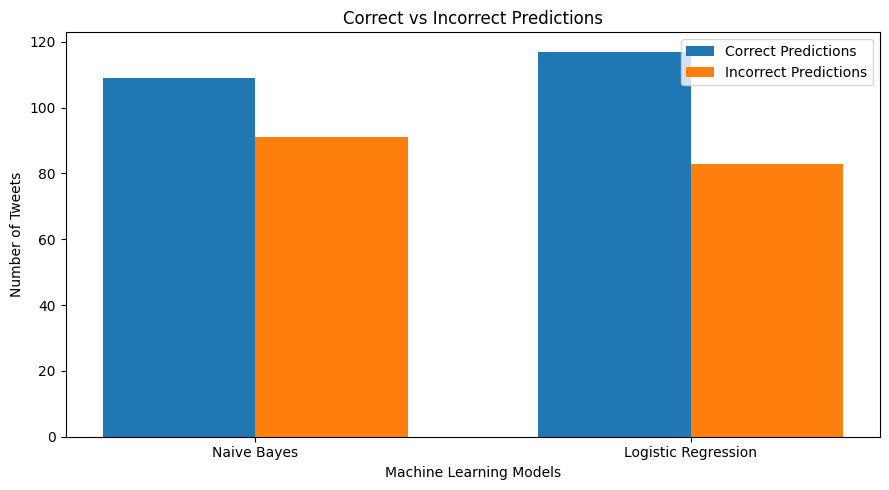

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Naive Bayes", "Logistic Regression"]
correct = [109, 117]
incorrect = [91, 83]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, correct, width, label="Correct Predictions")
plt.bar(x + width/2, incorrect, width, label="Incorrect Predictions")

plt.xlabel("Machine Learning Models")
plt.ylabel("Number of Tweets")
plt.title("Correct vs Incorrect Predictions")
plt.xticks(x, models)
plt.legend()

plt.tight_layout()
plt.show()

## 11. Sentiment Trends and Ethical Reflection

### 11.1 Sentiment Distribution

This section examines the distribution of positive, negative, and neutral sentiments in the selected Kenyan political tweets.

The sentiment labels were automatically generated using VADER.

SENTIMENT DISTRIBUTION
sentiment
positive    373
neutral     362
negative    265
Name: count, dtype: int64


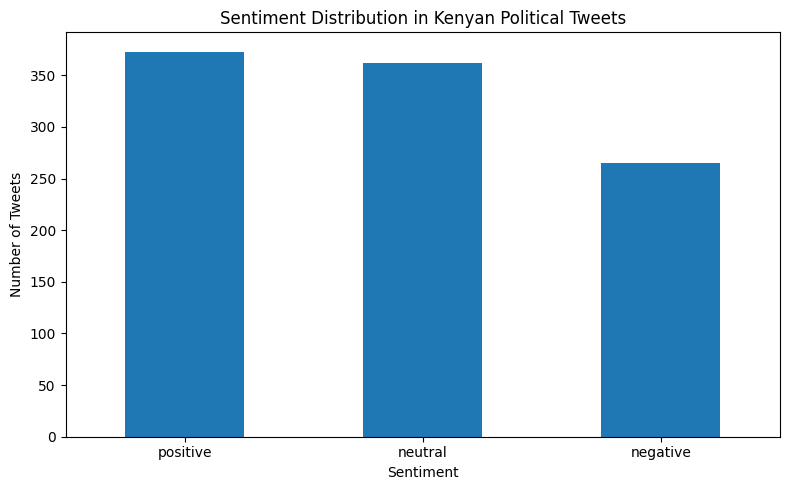

In [ ]:
import matplotlib.pyplot as plt

sentiment_counts = annotation_df["sentiment"].value_counts()

print("SENTIMENT DISTRIBUTION")
print(sentiment_counts)

plt.figure(figsize=(8, 5))

sentiment_counts.reindex(
    ["positive", "neutral", "negative"]
).plot(
    kind="bar",
    xlabel="Sentiment",
    ylabel="Number of Tweets",
    title="Sentiment Distribution in Kenyan Political Tweets"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 11.2 Interpretation of Sentiment Trends

The sentiment analysis identified three categories:

- Positive sentiment: 373 tweets (37.3%).
- Neutral sentiment: 362 tweets (36.2%).
- Negative sentiment: 265 tweets (26.5%).

Positive tweets represented the largest category, followed closely by neutral tweets. Negative tweets represented the smallest category.

These results suggest that the selected dataset contains a mixture of positive, neutral, and negative expressions about Kenyan political topics.

However, these results should not be interpreted as the general opinion of Kenyan citizens because the dataset is limited to selected social media posts and the sentiment labels were automatically generated using VADER.

### 11.3 Ethical Considerations

This project uses publicly available social media posts. However, several ethical limitations must be considered.

1. **Privacy:** Public tweets may contain personal information. The analysis should avoid exposing individual users.

2. **Bias:** The dataset may not represent all Kenyan citizens or political opinions.

3. **Language limitations:** VADER is mainly designed for English. It may misinterpret Swahili, Sheng, and Kenyan political expressions.

4. **Automatic labeling:** Sentiment labels were generated by VADER and were not manually verified. Therefore, some labels may be incorrect.

5. **Political sensitivity:** Sentiment classification can oversimplify political opinions and should not be treated as a definitive measure of public opinion.

## 12. Final Results and Conclusion

### 12.1 Model Performance Comparison

The two supervised machine learning models were evaluated using 200 test tweets.

| Metric | Naive Bayes | Logistic Regression |
|---|---:|---:|
| Accuracy | 54.50% | 58.50% |
| Precision | 61.90% | 58.44% |
| Recall | 54.50% | 58.50% |
| F1-score | 52.27% | 57.79% |

Logistic Regression achieved better accuracy, recall, and F1-score. Naive Bayes achieved higher weighted precision.

Overall, Logistic Regression performed better on this dataset.

### 12.2 Conclusion

This project applied supervised machine learning techniques to analyze sentiment in Kenyan political tweets.

A dataset of 11,723 tweets was initially collected. After removing missing values, duplicate tweets, and empty cleaned texts, a sample of 1,000 tweets was selected for sentiment annotation.

VADER was used to automatically assign positive, neutral, and negative labels. The annotated dataset was divided into 800 training tweets and 200 testing tweets.

Two machine learning models were trained: Naive Bayes and Logistic Regression.

Logistic Regression achieved an accuracy of 58.50%, compared with 54.50% for Naive Bayes. It also obtained a higher weighted F1-score of 57.79%.

Although Logistic Regression performed better overall, both models showed limitations in classifying political sentiment accurately.

The project demonstrates how machine learning can be applied to social media sentiment analysis. However, the results are limited by automatic sentiment labeling, possible language bias, and the representativeness of the dataset.